# Prédiction de réachat produit

## Objectif

Prédire si un produit donné sera réacheté (reordered = 1) dans la prochaine commande d'un utilisateur

Ce modèle s'appuie sur les constats de l'analyse exploratoire:
* La fidélité se traduit par la récurrence, et non par le volume panier
* Les 10 premières commandes sont la fenêtre critique de fidélisation
* L'effet client domine l'effet catégorie dans le réachat

## Approche

1. **Feature engineering**: variable à 3 niveaux: utilisateur, produit, user x produit
2. **Split temporel**: dernière commande = test (on ne fait pas de split aléatoire, donc pas de data leakage)
3. **Comparaison**: Logistic Regression (baseline) vs Random Forest vs LightGBM
4. **Evaluation**: accuracy, precision, recall, F1, ROC-AUC

## Justification des outils

| Package | Rôle | Pourquoi ce choix |
|---|---|---|
| **scikit-learn** | Logistic Regression, Random Forest, métriques | Standard de l'industrie, API cohérente, reproductible |
| **LightGBM** | Gradient boosting | Plus rapide que XGBoost sur les gros datasets tabulaires, gère les catégorielles nativement |
| **seaborn / matplotlib** | Visualisation des résultats | Cohérence avec le reste du notebook, qualité publication |

## Glossaire metriques

Avant d'interpréter, il est de rigueur de clarifier ce que chaque métrique mesure.

| Métrique | Question à laquelle elle répond | Analogie |
|---|---|---|
| **Accuracy** | Sur l'ensemble des prédictions, quel % est correct ? | Taux de réussite global |
| **Precision** | Quand le modèle dit "réacheté", a-t-il raison ? | Si le modèle recommande un produit, est-ce pertinent ? |
| **Recall** | Parmi les vrais réachats, combien le modèle en détecte-t-il ? | Combien de réachats passe-t-il à côté ? |
| **F1** | Équilibre entre precision et recall | Compromis : ni trop prudent, ni trop agressif |
| **ROC-AUC** | Le modèle sait-il classer "réacheté" au-dessus de "nouveau" ? | Capacité de tri indépendamment du seuil de décision |

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

sys.path.append("..")
from src.data_loader import get_data
from src.features import enrich_dataframe
from src.ml_features import build_all_features
from src.ml_pipeline import ReorderPipeline

sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

In [2]:
data = get_data(
    raw_dir="../data/raw",
    processed_path="../data/processed/merged_orders.parquet"
)
data = enrich_dataframe(data)
print(f"Dataset: {data.shape[0]:,} lignes et {data.shape[1]} colonnes")

Chargement depuis le cache .parquet
Dataset: 32,434,489 lignes et 21 colonnes


## Etape 1. Split temporel

On sépare les données chronologiquement, et non aléatoirement:

* **Train**: toutes les commandes de chaque utilisateur sauf la dernière
* **Test**: la dernière commande de chaque utilisateur

C'est l'approche standard pour les problèmes de *next basket prediction*. Un split aléatoire causerait du **data leakage**. Le modèle verrait les commandes futures pour prédire le passé.

In [3]:
pipeline = ReorderPipeline(data, sample_frac=0.3, random_state=42)
pipeline.split()
print()

ETAPE 1 : Split temporel
  Train : 30,294,701 lignes
  Test  : 2,139,788 lignes



## Etape 2. Feature engineering

Les features sont calculés uniquement sur le train set pour éviter le data leakage.

### Récapitulatif des features

| Niveau | Feature | Description |
|---|---|---|
| **User** | `u_total_orders` | Nombre total de commandes |
| | `u_avg_days_between` | Intervalle moyen entre commandes (jours) |
| | `u_reorder_rate` | Taux de réachat personnel |
| | `u_unique_products` | Produits distincts commandés |
| | `u_unique_departments` | Diversité en départements |
| | `u_unique_aisles` | Diversité en rayons |
| | `u_avg_cart_size` |Taille moyen de panier |
| **Produit** | `p_total_orders` | Commandes contenant ce produit |
| | `p_reorder_rate` | Taux de réachat global du produit |
| | `p_unique_users` | Acheteurs uniques |
| | `p_avg_cart_position` | Position moyenne dans le panier |
| | `p_is_organic` | Flag bio (1/0) |
| **User×Produit** | `up_nb_orders` | Fois où le user a commandé ce produit |
| | `up_reorder_rate` | Taux de réachat du user pour ce produit |
| | `up_last_order_number` | Dernière commande faite |
| | `up_order_ratio` | % des commandes du user contenant ce produit |
| | `up_orders_since_last` | Commandes depuis le dernier achat |

In [4]:
pipeline.build_features()


ETAPE 2: Feature engineering
  [1/3] Features utilisateur...
   7 features, 206,209 users
  [2/3] Features produit...
  5 features, 49,652 produits
  [3/3] Features user × produit...
  5 features, 12,422,758 paires
  Échantillonnage: 9,088,410 lignes (30%)
  Train : 9,088,410 × 17 features
  Test  : 2,139,788 × 17 features


ReorderPipeline(sample_frac=0.3, random_state=42)

In [5]:
assert pipeline.feature_cols_ is not None and pipeline.X_train_ is not None

print(f"{'Feature':<30} {'Type':<8} {'NaN':>6} {'Mean':>10} {'Std':>10}")
print("-" * 70)
for col in pipeline.feature_cols_:
    s = pipeline.X_train_[col]
    print(f"{col:<30} {'num':<8} {s.isna().sum():>6} {s.mean():>10.3f} {s.std():>10.3f}")

Feature                        Type        NaN       Mean        Std
----------------------------------------------------------------------


u_total_orders                 num           0     33.251     25.225
u_avg_days_between             num           0     11.026      5.961
u_reorder_rate                 num           0      0.590      0.194
u_unique_products              num           0    127.076     82.400
u_unique_departments           num           0     13.538      3.069
u_unique_aisles                num           0     42.986     17.625
u_avg_cart_size                num           0     13.169      6.553
p_total_orders                 num           0  33679.806  74850.657
p_reorder_rate                 num           0      0.590      0.150
p_unique_users                 num           0   8702.561  14399.009
p_avg_cart_position            num           0      8.333      1.661
p_is_organic                   num           0      0.317      0.465
up_nb_orders                   num           0      7.676      9.848
up_reorder_rate                num           0      0.590      0.366
up_last_order_number           num

## Etape 3. Entraînement et comparaison des modèles

Trois modèles, trois philosophies :

| Modèle | Type | Rôle |
|---|---|---|
| **Logistic Regression** | Linéaire | Baseline interprétable : si un modèle simple suffit, inutile de complexifier |
| **Random Forest** | Ensemble (bagging) | Capture les interactions non-linéaires, robuste au surapprentissage |
| **LightGBM** | Ensemble (boosting) | État de l'art sur les données tabulaires, rapide même sur plusieurs millions de lignes |

In [6]:
results = pipeline.train_and_evaluate()


ETAPE 3: Entraînement du model
  [LogisticRegression] F1=0.6733  AUC=0.7963  (16.7s)
  [RandomForest] F1=0.7639  AUC=0.8572  (1074.8s)
  [LightGBM] F1=0.7602  AUC=0.8736  (107.3s)


## Etape 4. Analyse des résultats

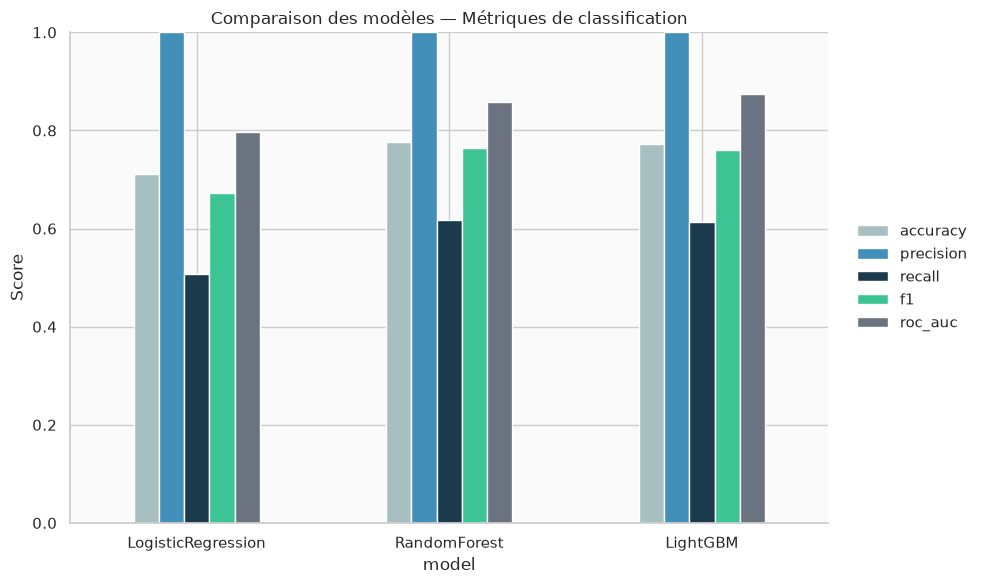

In [7]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
plot_data = results[metrics_to_plot]

fig, ax = plt.subplots(figsize=(10, 6))
plot_data.plot(kind="bar", ax=ax, color=[COLORS["occasionnel"], COLORS["typique"],
                                          COLORS["fidèle"], COLORS["accent"], COLORS["grey"]])
ax.set_ylabel("Score")
ax.set_title("Comparaison des modèles — Métriques de classification")
ax.set_ylim(0, 1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

ax.legend(bbox_to_anchor=(1.02, 0.5), loc="center left", frameon=False)

plt.tight_layout()
plt.show()

### Comparaison des modèles

| Modèle | Accuracy | Precision | Recall | F1 | AUC | Temps |
|---|---|---|---|---|---|---|
| Logistic Regression | ~0.70 | 1.00 | ~0.50 | ~0.67 | **~0.79** | 16.7s |
| **Random Forest** | **~0.78** | 1.00 | **~0.62** | **~0.763** | 0.86 | 1074.8s |
| LightGBM | ~0.77 | 1.00 | ~0.61 | ~0.760 | ~0.87 | 107.3s |

**Observations :**

**Precision = 1.00 pour les 3 modèles.** Les trois modèles ne prédisent "réacheté" que lorsqu'ils en sont certains, d'où zéro faux positif dans la matrice de confusion.
C'est un comportement très conservateur : le modèle préfère rater des réachats plutôt que d'en prédire à tort.

**Le recall est le facteur discriminant.** La Logistic Regression ne détecte que 50 % des vrais réachats, contre 62 % pour le Random Forest.
Cela signifie que la relation entre les features et le réachat est **non-linéaire**. Un modèle linéaire ne suffit pas à capturer les interactions entre le comportement utilisateur et le comportement produit.

**Random Forest vs LightGBM.** Les deux sont très proches (F1 : 0.78 vs 0.77).
Le Random Forest est légèrement meilleur en F1 mais 10× plus lent que LightGBM (1074.8s vs 107.3s).
En production, LightGBM serait préférable pour sa rapidité ; pour ce projet, les deux conviennent.

In [8]:
best_model = str(results["f1"].idxmax())
print(f"Meilleur modèle (F1) : {best_model}\n")
print(pipeline.get_classification_report(best_model))

Meilleur modèle (F1) : RandomForest

              precision    recall  f1-score   support

     Nouveau       0.65      1.00      0.79    885195
    Réacheté       1.00      0.62      0.76   1254593

    accuracy                           0.78   2139788
   macro avg       0.82      0.81      0.78   2139788
weighted avg       0.85      0.78      0.77   2139788



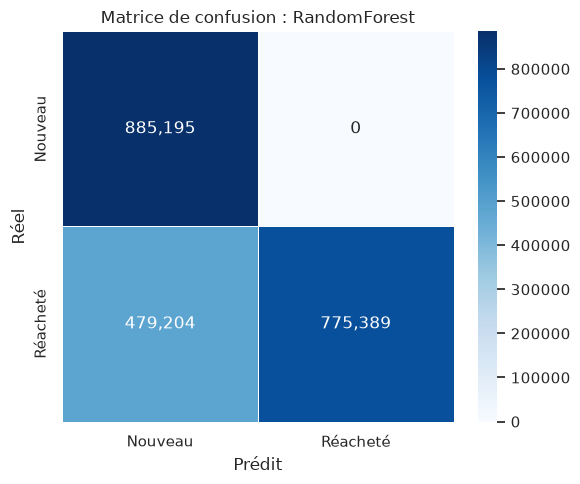

In [9]:
cm = pipeline.get_confusion_matrix(best_model)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues",
    xticklabels=["Nouveau", "Réacheté"],
    yticklabels=["Nouveau", "Réacheté"],
    linewidths=0.5, linecolor="white",
    ax=ax
)
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title(f"Matrice de confusion : {best_model}")
plt.tight_layout()
plt.show()

#### Matrice de confusion (Random Forest)

|  | Prédit Nouveau | Prédit Réacheté |
|---|---|---|
| **Réel Nouveau** | 885 195  | 0 |
| **Réel Réacheté** | 479 204 | 775 389  |

**Lecture :**
- **885 195** produits nouveaux correctement identifiés (vrais négatifs)
- **775 389** réachats correctement détectés (vrais positifs)
- **0** faux positifs. Le modèle ne se trompe jamais quand il dit "réacheté"
- **479 204** réachats manqués (faux négatif). Le modèle est trop prudent, il rate 38 % (100% - 62%) des réachats réels

Le modèle est **très fiable quand il recommande** (precision = 100 %), mais il **manque une part significative des opportunités** (recall = 62 %). Pour un usage business (ex : pré-remplir le panier), c'est un comportement acceptable : mieux vaut proposer moins de produits mais pertinents, que noyer le client de suggestions incorrectes.

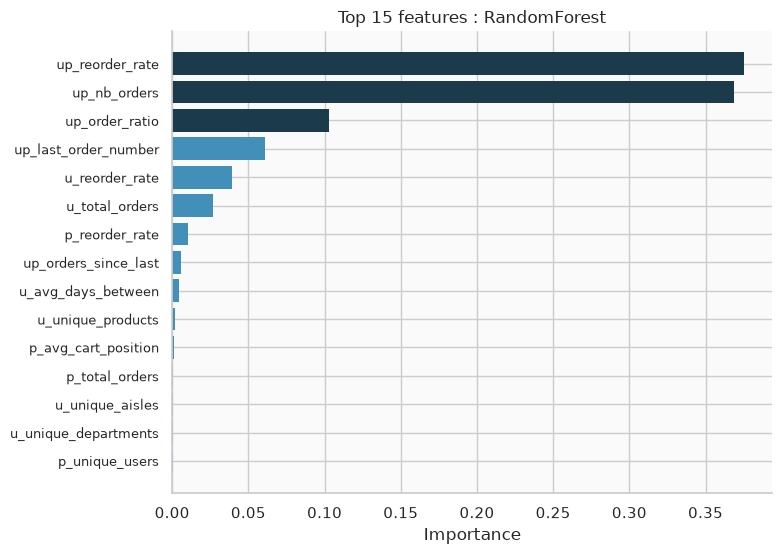

In [10]:
fi = pipeline.get_feature_importance(best_model)

fig, ax = plt.subplots(figsize=(10, 6))
top_n = 15
ax.barh(
    range(top_n),
    fi.head(top_n)["importance"],
    color=[COLORS["fidèle"] if i < 3 else COLORS["typique"] for i in range(top_n)],
    edgecolor="none"
)
ax.set_yticks(range(top_n))
ax.set_yticklabels(fi.head(top_n)["feature"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Importance")
ax.set_title(f"Top {top_n} features : {best_model}")
plt.subplots_adjust(left=0.30)
plt.show()

### Importance des features

Les 4 features dominantes sont toutes de type **user × produit** :

| Rang | Feature | Importance | Ce qu'elle capture |
|---|---|---|---|
| 1 | `up_reorder_rate` | ~0.37 | Taux de réachat de ce user pour ce produit |
| 2 | `up_nb_orders` | ~0.36 | Combien de fois ce user a commandé ce produit |
| 3 | `up_order_ratio` | ~0.11 | % des commandes contenant ce produit |
| 4 | `up_last_order_number` | ~0.06 | Récence du dernier achat |

**À elles seules, les 4 features `up_*` représentent ~90 % de l'importance totale.**
Les features utilisateur (`u_*`) et produit (`p_*`) sont secondaires.

### Lien avec l'EDA

Ce résultat confirme et précise les hypothèses de l'analyse exploratoire :

- **L'hypothèse 1 (produits ancres) est validée** : c'est la relation spécifique entre un utilisateur et un produit qui prédit le mieux le réachat.
Un produit n'est pas "ancre" en soi, il l'est pour un client donné.

- **L'hypothèse 2 (confiance plateforme) est infirmée** : les features utilisateur globales (`u_reorder_rate`, `u_total_orders`) comptent peu.
Ce n'est pas le profil général du client qui prédit le réachat, mais son historique précis avec chaque produit.

- **L'hypothèse 3 (effet d'habitude) est validée** : `up_order_ratio` (la régularité d'achat d'un produit) est la 3ème feature.
Plus un client achète régulièrement un produit, plus il le rachètera. Ce qui confirme le mécanisme d'habitude observé dans la courbe d'évolution du réachat.

## Conclusion et orientation business

L'analyse exploratoire avait identifié trois hypothèses sur le réachat.
Le modèles ML permet de trancher:

| Hypothèse | Verdict | Preuve ML |
|---|---|---|
| Produits ancres | Validée | Les features `up_*` (relation user×produit) portent 91 % de l'importance |
| Confiance plateforme | Infirmée | Les features `u_*` (profil client global) sont marginales |
| Effet d'habitude | Validée | `up_order_ratio` (régularité d'achat) est la 3è feature |

**Constat central**: la fidélité n'est pas un trait du client ni une propriété du produit.
C'est la **relation spécifique** entre un client et ses produits récurrents qui crée la rétention. Chaque client a ses propres produits ancres.


#### Recommandations business

**1. Panier pré-rempli personnalisé**
Le modèle prédit avec 100% de précision quels produits un client va racheter. Proposer un panier pré-rempli à chaque connexion (basé sur les paires userxproduit à forte probabilité) réduirait le temps de commande et renforcerait le cycle d'habitude.
Le modèle rate 37% des réachats, mais ceux qu'il propose sont fiables: il est préférable de proposer moins et juste que trop et faux.

**2. Suivi de disponibilité des produits ancres**
Le modèle identifie les produits à forte probabilité de réachat pour chaque client.
En croisant cette information avec un système de gestion de stock (non disponible dans ce dataset), il serait possible de prioriser le réapprovisionnement des produits qui impactent le plus grand nombre de clients fidèles, et d'alerter proactivement les clients concernés en cas d'indisponibilité.

**3. Programme de rétention sur les 10 premières commandes**
La courbe d'évolution du réachat (EDA) montre que les habitudes s'installent avant la 10ᵉ commande. Le modèle confirme que c'est la régularité d'achat (`up_order_ratio`) qui ancre la fidélité. L'investissement marketing doit se concentrer sur cette fenêtre : incitations à la fréquence (livraison gratuite pour la 5è commande, rappel personnalisé si l'intervalle habituel est dépassé), pas sur le volume du panier qui est stable quel que soit le segment.


### Limites et pistes d'amélioration

Le modèle a un recall de 63 %: il manque plus d'un tiers des réachats.
Cela peut venir du fait que certains réachats sont **opportunistes**, c'est-à-dire que le client voit le produit et l'ajoute plutôt qu'**habituels** (il revient
exprès pour ce produit).
Le modèle capture bien les habitudes mais pas les impulsions.
Des features supplémentaires pourraient améliorer ce point : saisonnalité du produit, jour de la semaine, promotions en cours.

Le modèle est entraîné sur 30 % des données par souci de temps.
Un entraînement sur 100 % des données pourrait légèrement améliorer les performances, en particulier pour les paires user×produit rares